In [1]:
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

#### Residual Network Background

The fundamental premise of Residual Networks (ResNets) is the mitigation of the **degradation problem** in ultra-deep neural networks. As traditional convolutional networks grow deeper (e.g., stacking 50 or 100 layers), their training error paradoxically increases. This is not caused by overfitting, but rather because standard optimization algorithms struggle to navigate the exponentially complex hypothesis space, making it nearly impossible for deep layers to learn even simple identity mappings.

ResNets solve this by fundamentally altering the mathematical mapping of the layers using **skip connections** (or shortcut connections).


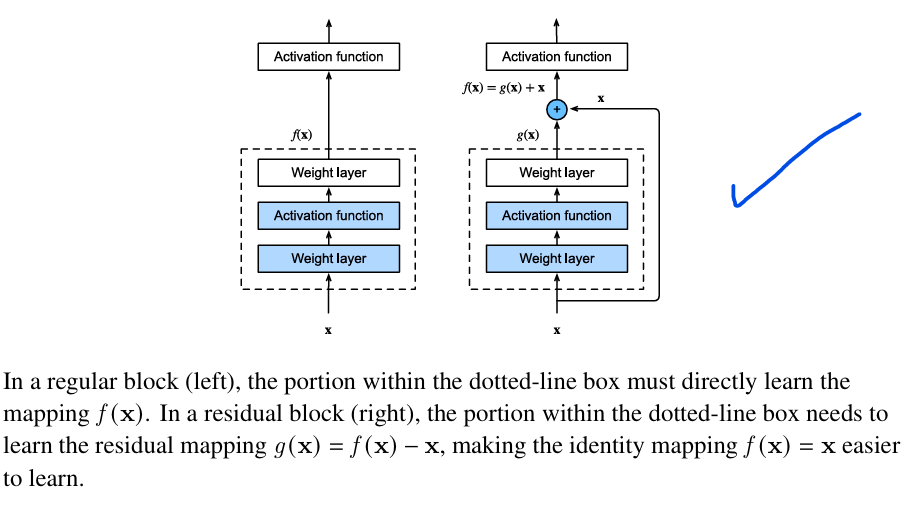

### 1. The Mathematics of the Forward Pass

In a standard feed-forward network, we stack non-linear layers and hope they directly approximate a complex underlying target function, which we will call $\mathcal{H}(x)$.

The ResNet architecture argues that it is excessively difficult for a stack of non-linear layers to learn the exact identity mapping ($\mathcal{H}(x) = x$). Therefore, instead of forcing the layers to learn the complete transformation $\mathcal{H}(x)$, we force them to learn the **residual mapping**, denoted as $\mathcal{F}(x)$.

We redefine our target function as:


$$\mathcal{H}(x) = \mathcal{F}(x) + x$$

Rearranging this, the layers are now only responsible for learning the difference (the residual) between the input and the output:


$$\mathcal{F}(x) = \mathcal{H}(x) - x$$

In code and architecture, this is implemented by taking the input $x$, passing it through a few convolutional layers to compute $\mathcal{F}(x)$, and then performing an element-wise addition with the original input $x$ before the final ReLU activation:


$$y = \text{ReLU}(\mathcal{F}(x, \{W_i\}) + x)$$

### 2. The Function Class Perspective (Theoretical Guarantee)

Relating this back to our discussion on function classes, ResNets provide a strict mathematical guarantee regarding capacity.

If you add a new block of layers to a standard CNN, you fundamentally alter the hypothesis space. There is no guarantee the new space contains the optimal function found by the shallower network.

However, in a ResNet, the new, deeper function class strictly subsumes the shallower one. If the optimal mapping for a layer is simply the identity function (meaning no further transformations are needed), the solver simply drives the weights of $\mathcal{F}(x)$ to zero.
If $\mathcal{F}(x) = 0$, then $\mathcal{H}(x) = 0 + x = x$.
Because it is trivially easy for neural networks to push weights to zero via L2 regularization (Weight Decay), deeper ResNets are mathematically guaranteed to perform at least as well as their shallower counterparts.

### 3. The Mathematics of Backpropagation (The True Power)

The true brilliance of ResNets is revealed during backpropagation. To see why they completely eliminate the vanishing gradient problem, we can unroll the recursive formula of a residual block.

Let $x_l$ be the input to the $l$-th residual block, and $x_{l+1}$ be its output:


$$x_{l+1} = x_l + \mathcal{F}(x_l, \mathcal{W}_l)$$

If we apply this recursively from a shallow layer $l$ to a much deeper layer $L$, we get:


$$x_L = x_l + \sum_{i=l}^{L-1} \mathcal{F}(x_i, \mathcal{W}_i)$$

This equation shows that the feature $x_L$ of any deep layer is the exact feature of a shallow layer $x_l$ plus the sum of all the residuals in between.

Now, let $\mathcal{E}$ be the loss function. Using the chain rule, the gradient of the loss with respect to the shallow layer $x_l$ is:


$$\frac{\partial \mathcal{E}}{\partial x_l} = \frac{\partial \mathcal{E}}{\partial x_L} \frac{\partial x_L}{\partial x_l}$$

Substituting our recursive equation into the derivative yields the definitive ResNet gradient equation:


$$\frac{\partial \mathcal{E}}{\partial x_l} = \frac{\partial \mathcal{E}}{\partial x_L} \left( 1 + \frac{\partial}{\partial x_l} \sum_{i=l}^{L-1} \mathcal{F}(x_i, \mathcal{W}_i) \right)$$

This equation is why ResNets can be trained to depths of 1,000 layers or more:

* **The Unhindered Path (The "$1$"):** The scalar $1$ propagates the gradient $\frac{\partial \mathcal{E}}{\partial x_L}$ directly back to any shallow layer $l$ without any weight matrices multiplying it, meaning the gradient literally cannot vanish.
* **The Residual Path:** The summation term routes the gradients through the weight matrices to actually update the parameters. Even if this entire summation term evaluates to $0$ (which causes the vanishing gradient in standard networks), the $1$ guarantees the error signal survives to the beginning of the network.

### 4. The Bottleneck Architecture

Similar to GoogLeNet's Inception module, ultra-deep ResNets (like ResNet-50, ResNet-101) use a **Bottleneck Block** to maintain computational feasibility.
Instead of two $3 \times 3$ convolutions, a bottleneck block uses three layers:

1. A $1 \times 1$ convolution to reduce the channel dimensions (the bottleneck).
2. A $3 \times 3$ convolution applied to the compressed dimensions.
3. A $1 \times 1$ convolution to restore the channel dimensions back to their original size so the skip connection addition ($+ x$) aligns perfectly.


### Forward and Backward pass in ResNet

# Forward Propagation

If the output of the $\ell$-th residual block is the input to the $(\ell+1)$-th residual block (assuming no activation function between blocks), then the $(\ell+1)$-th input is:

$$
x_{\ell+1} = F(x_\ell) + x_\ell
$$

Applying this formulation recursively, we obtain:

$$
\begin{aligned}
x_{\ell+2} &= F(x_{\ell+1}) + x_{\ell+1} \\
&= F(x_{\ell+1}) + F(x_\ell) + x_\ell
\end{aligned}
$$

This yields the general relationship:

$$
\boxed{
x_L = x_\ell + \sum_{i=\ell}^{L-1} F(x_i)
}
$$

where $L$ is the index of a residual block and $\ell$ is the index of some earlier block. This formulation suggests that there is always a signal that is directly sent from a shallower block $\ell$ to a deeper block $L$.

# Backward Propagation

The residual learning formulation provides the added benefit of mitigating the vanishing gradient problem to some extent. However, it is crucial to acknowledge that the vanishing gradient issue is not the root cause of the degradation problem, which is tackled through the use of normalization.

To observe the effect of residual blocks on backpropagation, consider the partial derivative of a loss function $\mathcal{E}$ with respect to some residual block input $x_\ell$.

Using the equation derived above for forward propagation, for a later residual block $L > \ell$, we obtain:

$$
\begin{aligned}
\frac{\partial \mathcal{E}}{\partial x_\ell}
&= \frac{\partial \mathcal{E}}{\partial x_L}
\frac{\partial x_L}{\partial x_\ell} \\[8pt]
&= \frac{\partial \mathcal{E}}{\partial x_L}
\left(
1 + \frac{\partial}{\partial x_\ell}
\sum_{i=\ell}^{L-1} F(x_i)
\right) \\[8pt]
&= \frac{\partial \mathcal{E}}{\partial x_L}
+ \frac{\partial \mathcal{E}}{\partial x_L}
\frac{\partial}{\partial x_\ell}
\sum_{i=\ell}^{L-1} F(x_i)
\end{aligned}
$$

This formulation suggests that the gradient computation of a shallower layer,

$$
\frac{\partial \mathcal{E}}{\partial x_\ell},
$$

always contains a later term,

$$
\frac{\partial \mathcal{E}}{\partial x_L},
$$

that is directly added.

Even if the gradients of the $F(x_i)$ terms are small, the total gradient

$$
\frac{\partial \mathcal{E}}{\partial x_\ell}
$$

resists vanishing due to the added term

$$
\frac{\partial \mathcal{E}}{\partial x_L}.
$$

In [6]:
class Residual(nn.Module):
    def __init__(self, num_channels, use_1x1conv=False, strides=1):
        super().__init__()

        self.conv1 = nn.LazyConv2d(num_channels, kernel_size=3, padding=1, stride=strides)
        self.conv2 = nn.LazyConv2d(num_channels, kernel_size=3, padding=1)

        if use_1x1conv:
            self.conv3 = nn.LazyConv2d(num_channels, kernel_size=1, stride=strides)
        else: 
            self.conv3 = None

        self.bn1 = nn.LazyBatchNorm2d()
        self.bn2 = nn.LazyBatchNorm2d()

    def forward(self, X):
        Y = F.relu(self.bn1(self.conv1(X)))
        Y = self.bn2(self.conv2(Y))
        if self.conv3 is not None:
            X = self.conv3(X)
        Y += X
        return F.relu(Y)

In [7]:
blk = Residual(3)
X = torch.randn(4, 3, 6, 6)
blk(X).shape

torch.Size([4, 3, 6, 6])

In [8]:
X = torch.randn(4, 3, 6, 6)
blk = Residual(6, use_1x1conv=True, strides=2)
blk(X).shape

torch.Size([4, 6, 3, 3])